# 04 Degradation, soiling and external weather - PVDAQ system 9069

Goal of Phase 4: split the shortfall of the running inverters against the model (Phase 3) into
causes that can be measured, and test the on-site sensors against independent weather data.
Logic lives in `src/pv_loss_auditor/degradation.py` and `src/pv_loss_auditor/openmeteo.py`; this notebook runs it and states conclusions.

Decisions (taken with me, options first):
- RdTools input: **both** normalized energy (measured / PVWatts expected) and PR (C), running inverters only.
- Shortfall is split by **per-factor estimates plus a residual** that is shown as uncertainty, not forced to zero.
- Open-Meteo: **ERA5 and ECMWF IFS**. The satellite API has no coverage at 9069, so nothing here is satellite data.
- AOI: ASHRAE, b0 = 0.05 (an upper bound, see section 5).

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pv_loss_auditor import degradation as dg
from pv_loss_auditor import model, openmeteo as om
from pv_loss_auditor.config import load_config

cfg = load_config("configs/system_9069.yaml")
inputs, ac = model.load_inputs(cfg)
t_cell = model.cell_temperature(inputs, cfg)
FIG = Path("reports/figures")

## 1. Daily series for RdTools
Running inverters only; a day is kept with >= 90 % usable inverter-steps, >= 50 % of them running and >= 2 kWh/m2 insolation.

In [2]:
daily = dg.daily_series(inputs, ac, t_cell, cfg)
print(daily[["energy_norm", "pr_wc"]].describe().round(3))
print("kept days:", int(daily.energy_norm.notna().sum()), "of", len(daily))
print(daily.groupby(daily.index.year).energy_norm.agg(["median", "count"]).round(3))

       energy_norm     pr_wc
count     1093.000  1093.000
mean         0.885     0.754
std          0.029     0.026
min          0.790     0.661
25%          0.866     0.737
50%          0.886     0.756
75%          0.907     0.774
max          0.967     0.828
kept days: 1093 of 1309
          median  count
time_utc               
2020       0.902    214
2021       0.890    304
2022       0.895    300
2023       0.865    275


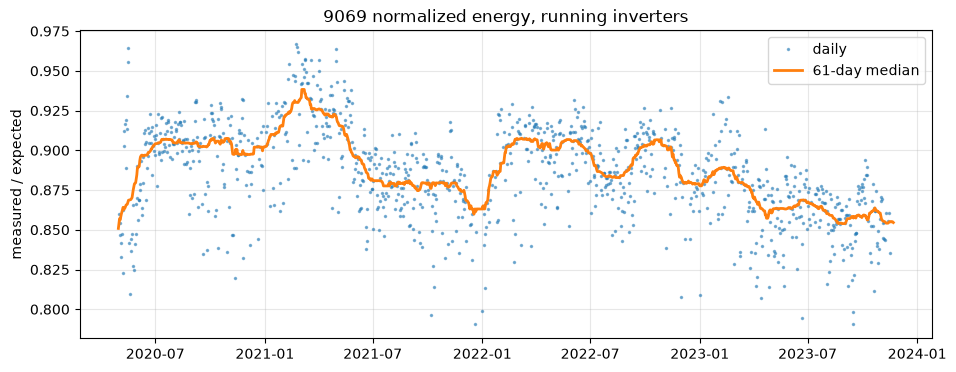

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily.energy_norm, ".", ms=3, alpha=.5, label="daily")
ax.plot(daily.energy_norm.rolling(61, min_periods=20, center=True).median(), lw=2, label="61-day median")
ax.set(ylabel="measured / expected", title="9069 normalized energy, running inverters"); ax.legend(); ax.grid(alpha=.3)
fig.savefig(FIG / "9069_normalized_energy.png", dpi=130, bbox_inches="tight"); plt.show()

## 2. Degradation (RdTools year-on-year)
YoY compares each day with the same day one year later, so the season cancels; the median of all pairs is robust to outlier days.

In [4]:
print(dg.yoy_table(daily).round(2).to_string(index=False))

     series     period  days  rd_pct_yr  ci_low  ci_high
energy_norm       full  1093      -1.68   -1.93    -1.49
energy_norm to 2022-12   818      -0.51   -0.81    -0.31
      pr_wc       full  1093      -1.78   -1.95    -1.46
      pr_wc to 2022-12   818      -0.43   -0.89    -0.31


### Sensitivity to the day filters
The filters are my assumptions, so the rate is recomputed on a grid.

In [5]:
sens = dg.filter_sensitivity(inputs, ac, t_cell, cfg, [1, 2, 3, 4], [0.25, 0.5, 0.8])
pre = sens[sens.period.str.startswith("to")]
print("to 2022-12: range of rate over the grid:", pre.rd_pct_yr.min().round(2), "...", pre.rd_pct_yr.max().round(2))
print(sens.pivot_table(index=["min_poa", "min_running"], columns="period", values="rd_pct_yr").round(2))

to 2022-12: range of rate over the grid: -1.26 ... -0.48
period               full  to 2022-12-31
min_poa min_running                     
1       0.25        -1.81          -0.59
        0.50        -1.84          -0.66
        0.80        -1.69          -1.12
2       0.25        -1.63          -0.48
        0.50        -1.68          -0.51
        0.80        -1.55          -1.05
3       0.25        -1.74          -0.54
        0.50        -1.78          -0.56
        0.80        -1.69          -1.06
4       0.25        -1.95          -0.98
        0.50        -2.00          -0.99
        0.80        -1.81          -1.26


**Conclusion.** The two series agree (within 0.1 pp). Before 2023 the rate is **-0.5 ... -1.3 %/yr** depending on the filters:
the confidence interval of RdTools (+-0.3) does not include this choice. Strict filters drop winter days and days with stopped
inverters, so the sample changes composition; I read part of the spread as that (hypothesis, not tested). With 2023 included
the rate is -1.6 ... -2.0 %/yr: that is a **step**, not ageing (section 3). Cell drift of +-1 %/yr (Phase 1) is added as uncertainty.
Statement for the README: *about -1 %/yr +- 0.5 before 2023*, never a single decimal.

## 3. Soiling (RdTools SRR)
ERA5 rain is the cleaning information. A day with rain >= threshold counts as a cleaning; the threshold is an assumption, so it is varied.

In [6]:
era5, ifs = om.fetch("era5", cfg), om.fetch("ifs", cfg)
rain = dg.daily_precipitation(era5)
print("rain days >= 2 mm per year:", (rain >= 2).groupby(rain.index.year).sum().to_dict())
print("rain mm per year (2020 is May-Dec):", rain.groupby(rain.index.year).sum().round(0).to_dict())
soil = dg.soiling_table(daily, rain)
print(soil.round(4).to_string(index=False))
last = soil.iloc[-1]
print(last["period"], ",", last["cleaning_info"], ": ratio", round(last["ratio"], 4), "-> loss", round(last["loss_pct"], 2), "%")

rain days >= 2 mm per year: {2020: 70, 2021: 115, 2022: 112, 2023: 103}
rain mm per year (2020 is May-Dec): {2020: 821.0, 2021: 1333.0, 2022: 1232.0, 2023: 1142.0}


        cleaning_info     period  ratio  ci_low  ci_high  valid  intervals  loss_pct
    upward jumps only       full 0.9732  0.9663   0.9789     18         56    2.6774
 rain >= 1 mm + jumps       full 0.9837  0.9799   0.9876     11         28    1.6293
 rain >= 2 mm + jumps       full 0.9862  0.9827   0.9893     10         27    1.3790
 rain >= 5 mm + jumps       full 0.9886  0.9849   0.9912      9         16    1.1427
rain >= 10 mm + jumps       full 0.9919  0.9895   0.9942      5          7    0.8055
 rain >= 2 mm + jumps to 2022-12 0.9872  0.9835   0.9902      7         17    1.2806
to 2022-12 , rain >= 2 mm + jumps : ratio 0.9872 -> loss 1.28 %


**Conclusion.** Soiling costs **about 1.4 % of expected energy** (1.1 - 1.6 % for rain thresholds 1 - 5 mm). Without rain data the
estimate was 2.7 %, which is too high: RdTools mistook noise jumps for cleanings. Georgia has ~100 rain days >= 2 mm per year,
so the plant is washed often. Only 10 - 11 of 27 - 28 intervals are valid, so the number is an order of magnitude, not a measurement.
The ratio before 2023 is the same as for the whole period: soiling does **not** explain the 2023 step (soiling looks like a saw-tooth, the step is a permanent shift).

## 4. On-site sensors vs Open-Meteo
Hourly POA of both sources, transposed to 20/180 with Perez (their own DNI/DHI), against the reference-cell mean.

source  hours  mbe_pct  nrmse_pct    r
  era5   9859     1.60      22.13 0.85
   ifs   9859     1.97      22.71 0.84
             era5    ifs
time_utc                
2021-04-01  1.058  1.069
2021-10-01  1.052  1.059
2022-04-01  1.052  1.049
2022-10-01  1.053  1.054
2023-11-01  1.056  1.089


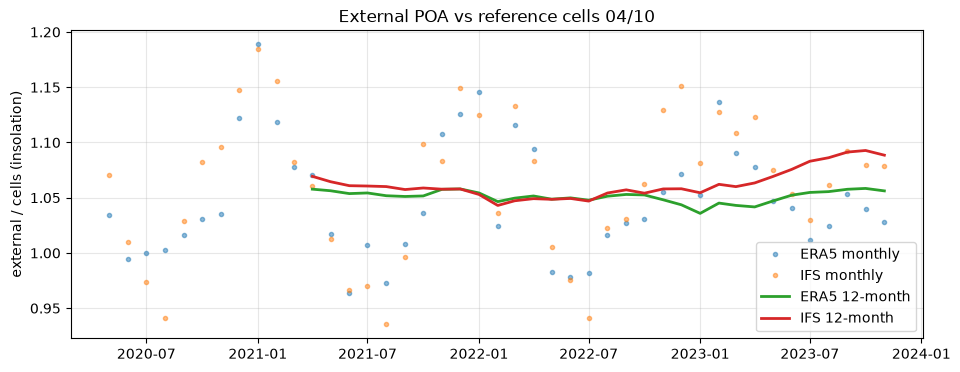

In [7]:
ext = {"era5": om.poa_from_weather(era5, cfg), "ifs": om.poa_from_weather(ifs, cfg)}
stats, ratio_all = dg.external_poa_comparison(dg.hourly_plant_poa(inputs["poa_wm2"]), ext)
print(stats.round(2).to_string(index=False))

ratio_all = ratio_all["2020-05-01":]    # the first month starts on the local evening of 30 April
ratio = ratio_all[["era5", "ifs"]]
roll = ratio_all[["era5_12m", "ifs_12m"]].rename(columns=lambda c: c[:-4])
print(roll.dropna().iloc[[0, 6, 12, 18, -1]].round(3))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ratio, ".", alpha=.5); ax.plot(roll, lw=2)
ax.legend(["ERA5 monthly", "IFS monthly", "ERA5 12-month", "IFS 12-month"]); ax.grid(alpha=.3)
ax.set(ylabel="external / cells (insolation)", title="External POA vs reference cells 04/10")
fig.savefig(FIG / "9069_external_poa_ratio.png", dpi=130, bbox_inches="tight"); plt.show()

In [8]:
pr = dg.pr_by_poa_source(inputs, ac, cfg, ext)
print("annual raw PR (A) of running inverters by POA source"); print(pr.round(3))
print("relative to the plant sensors"); print(pr.div(pr.plant, axis=0).round(3))

annual raw PR (A) of running inverters by POA source
          plant   era5    ifs
time_utc                     
2020      0.756  0.735  0.728
2021      0.765  0.729  0.732
2022      0.765  0.729  0.723
2023      0.731  0.691  0.672
relative to the plant sensors
          plant   era5    ifs
time_utc                     
2020        1.0  0.972  0.963
2021        1.0  0.954  0.957
2022        1.0  0.953  0.945
2023        1.0  0.944  0.919


**Conclusions.** (1) Open-Meteo overestimates POA by 1.6 - 2.0 % at hours above 200 W/m2 and by 3 - 6 % in monthly energy; hourly nRMSE
is 22 %, so it cannot be used for hour-level anomaly work. (2) PR from Open-Meteo is **2 - 6 pp lower** than from the cells (e.g. 0.69 vs 0.73 in 2023), larger
than any year-to-year change: a plant without sensors would look worse by that much. (3) The 12-month ratio ERA5 / cells is flat
(1.058 -> 1.056): the cells did **not** drift and the 2023 step is **not** a sensor effect. IFS rises (1.05 -> 1.09), which I attribute to
model versions of ECMWF (hypothesis; ERA5 does not show it). (4) The ratio is +10 ... +19 % in winter and -4 ... +4 % in summer: either the
reanalysis or the cells misread low sun; the data cannot say which.

## 5. Angle-of-incidence (reflection) loss
ASHRAE b0 = 0.05 for the beam, Marion's integrated IAM for sky and ground light, ERA5 components on the 20/180 plane.

In [9]:
poa_e = ext["era5"]
aoi = {b0: dg.weighted_loss_pct(poa_e, om.aoi_loss(era5, cfg, b0=b0)) for b0 in (0.03, 0.05, 0.07)}
print("period AOI loss, % of POA, by b0:", {k: round(v, 2) for k, v in aoi.items()})
d = pd.DataFrame({"poa": poa_e, "lost": poa_e * om.aoi_loss(era5, cfg)})
d.index = d.index.tz_convert("America/New_York")
d = d["2020-05-01":]    # drop the first local evening of 30 April
m = d.groupby([d.index.year, d.index.month]).sum()
print((m.lost / m.poa * 100).unstack(0).round(2))

period AOI loss, % of POA, by b0: {0.03: 1.79, 0.05: 2.95, 0.07: 4.09}
time_utc  2020  2021  2022  2023
time_utc                        
1          NaN  3.24  3.17  3.40
2          NaN  2.90  2.90  2.97
3          NaN  2.80  2.73  2.76
4          NaN  2.71  2.89  2.76
5         3.03  3.05  3.01  3.07
6         3.14  3.15  3.02  3.10
7         2.93  2.95  3.06  3.00
8         2.87  2.82  2.93  2.79
9         2.73  2.74  2.72  2.70
10        2.84  2.92  2.84  2.88
11        3.08  3.03  3.10  3.06
12        3.25  3.39  3.40   NaN


**Conclusion.** AOI costs **<= 3.0 % of POA** (1.8 - 4.1 % for b0 0.03 - 0.07), flat over the seasons (Nov-Dec only 0.3 - 0.5 pp above summer) and over the years.
It therefore explains neither the November-December PR dip nor the 2023 step. It is an **upper bound**: the reference cells sit under glass too,
so only the difference between module and cell IAM enters measured / model.

## 6. Where the shortfall of the running inverters goes

In [10]:
is_main = (soil.cleaning_info == "rain >= 2 mm + jumps") & (soil.period == "full")
soil_loss = float(soil.loc[is_main, "loss_pct"].iloc[0])
t = dg.shortfall_split(daily, soil_loss, aoi[0.05])
print(t.round(1))
short = t["shortfall_pct"]
print("2023 minus 2020-22 mean shortfall (pp):", round(short[2023] - short[[2020, 2021, 2022]].mean(), 1))

      shortfall_pct  soiling_pct  aoi_upper_bound_pct  unexplained_min_pct  \
year                                                                         
2020            9.8          1.4                  3.0                  5.4   
2021           11.0          1.4                  3.0                  6.6   
2022           10.5          1.4                  3.0                  6.2   
2023           13.5          1.4                  3.0                  9.2   

      unexplained_max_pct  
year                       
2020                  8.4  
2021                  9.6  
2022                  9.1  
2023                 12.2  
2023 minus 2020-22 mean shortfall (pp): 3.1


**Reading the table** (all in % of expected energy; 1 - median daily measured / expected):
- **Soiling ~1.4 %** (measured with RdTools + rain), **AOI 0 - 3 %** (upper bound), together at most ~4.4 %.
- **5.4 - 9.6 % stay unexplained** in 2020 - 22 (**9.2 - 12.2 %** in 2023). It mixes the error of the assumed 6.34 % design DC losses (Phase 3: 4 / 8 % moves the running shortfall by +4.3 / -3.1 GWh),
  low-light behaviour that linear PVWatts does not have, degradation since commissioning (age of the plant unknown) and sensor bias. The data cannot separate them;
  it is shown as a range on purpose.
- **2023 is ~3 pp worse** than 2020 - 22. Soiling (section 3), AOI (section 5), cell drift (section 4) and downtime (excluded) do not explain it.
  Candidates: failed strings / combiner boxes in the running inverters, or plant-level changes. That is material for Phase 5 (residual anomalies), not a conclusion.